# Historical U.S. Industrial Corporate Investment: Does a Lagged Valuation-to-Capital Proxy Forecast Firm Capex?

**Retrospective 11-firm Grunfeld panel | 1935–1954 | prepared 2026-10-27**

**Scope:** real firm-level gross investment (not an industry production index, not securities returns, and not an investable alpha strategy). The 1958 reconstructed data cannot establish contemporaneous point-in-time tradability. This notebook is designed to be independently readable and to run from the frozen CSV with archived robustness tables.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from analysis import (load_raw,prepare,walkforward,metrics,improvement,rank_diagnostics,
                      leave_one_company_out,BASE,FACTOR,FIRMS)
plt.rcParams['figure.dpi']=80
ROOT=Path.cwd()
S=json.loads((ROOT/'results/summary.json').read_text())
print('Frozen panel:', S['data_observations'],'rows,',S['n_firms'],'firms; OOS:',S['oos_firm_years'],'firm-years')

Frozen panel: 220 rows, 11 firms; OOS: 110 firm-years


## 01. Abstract

**Research question:** After controlling for past investment, installed capital and investment momentum, does a stale valuation-to-capital proxy improve forecasts of next-year gross corporate investment in the historical Grunfeld industrial-firm panel? We compare against firm-specific historical mean and persistence, not merely a weak regression baseline. The empirical test has 11 named firms, 10 test years and 110 firm-year forecasts. Its verdict is a retrospective fundamental-prediction claim only, never equity return alpha.

In [2]:
score=pd.read_csv(ROOT/'results/baseline_scorecard.csv')
print(score.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('Control minus full RMSE:',round(S['control_minus_full_rmse'],6))

          model   n  rmse_log  mae_log  rmse_invest_millions_1947
historical_mean 110    0.5358   0.4520                   146.3435
    persistence 110    0.2544   0.1990                    60.8373
        control 110    0.2929   0.2226                    77.4115
           full 110    0.2616   0.2029                    74.5713
Control minus full RMSE: 0.031281


## 02. Research Design & Hypotheses

**H1 (incremental fundamentals):** lagged market-to-capital improves log investment RMSE against a fixed multivariate control. **H2 (rank breadth):** the factor predicts within-year cross-firm investment residual ranks, not just levels. **H3 (robustness):** improvement survives company exclusion, ±20% proxy scaling, vintage correction, alternate lags and postwar subsamples. The null is zero or negative incremental OOS gain. Models, periods and alpha=12 are frozen for this experiment; they are not selected after seeing the scorecard. These are retrospective tests, not a clean prospective preregistration.

In [3]:
hypotheses=pd.DataFrame([
 ['H1','control RMSE - full RMSE > 0','OOS paired RMSE'],
 ['H2','positive residual-rank IC across years','within-year Spearman'],
 ['H3','same sign under perturbations/LOCO/regimes','robustness tables']
],columns=['Hypothesis','Expected direction','Test']);display(hypotheses)

,Hypothesis,Expected direction,Test
0,H1,control RMSE - full RMSE > 0,OOS paired RMSE
1,H2,positive residual-rank IC across years,within-year Spearman
2,H3,same sign under perturbations/LOCO/regimes,robustness tables


## 03. Industry Context

The dataset covers **11 large, historically selected U.S. industrial firms**, including automotive, steel, petroleum, electrical equipment, rubber, business machines and consumer materials. It is not a representative or survivorship-free sample of the U.S. manufacturing sector. Capital spending is economically related to installed productive capacity; market valuation can proxy for investment opportunities, but financial frictions and market-value measurement complicate a simple q-theory interpretation. The financing-constraint mechanism is discussed in Fazzari, Hubbard & Petersen (NBER 1987), published after the sample period.

In [4]:
exposure=pd.read_csv(ROOT/'data/company_exposure_map.csv');display(exposure[['firm','descriptive_industry','confidence','quantitative_revenue_weight']]);print('Unique firms:',exposure.firm.nunique())

,firm,descriptive_industry,confidence,quantitative_revenue_weight
0,American Steel,Metals,C,UNKNOWN
1,US Steel,Metals,C,UNKNOWN
2,Atlantic Refining,Petroleum,C,UNKNOWN
3,Union Oil,Petroleum,C,UNKNOWN
4,Chrysler,Automotive,C,UNKNOWN
5,General Motors,Automotive,C,UNKNOWN
6,General Electric,Electrical/industrial,C,UNKNOWN
7,Westinghouse,Electrical/industrial,C,UNKNOWN
8,Goodyear,Tires/rubber,C,UNKNOWN
9,IBM,Business machines,C,UNKNOWN


Unique firms: 11


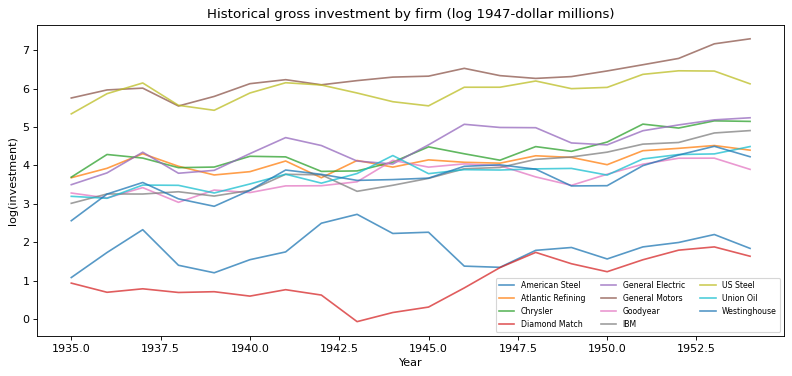

In [5]:
raw=load_raw(ROOT)
fig,ax=plt.subplots(figsize=(10,4.8))
for firm,g in raw.groupby('firm'):
    ax.plot(g.year,np.log(g.invest),alpha=.75,label=firm)
ax.set(title='Historical gross investment by firm (log 1947-dollar millions)',xlabel='Year',ylabel='log(investment)')
ax.legend(ncol=3,fontsize=7);plt.tight_layout();plt.show()

## 04. Data & Source Integrity

**Grade B** data: installed `statsmodels` 0.14.6 Grunfeld package, 220 firm-years from 1935–1954, copied without editing into `data/grunfeld_statsmodels_0_14_6_frozen.csv` and hashed. **Grade A** original Grunfeld 1958 dissertation is attributed by the package and AER documentation but was not independently inspected. **Grade B** independent AER documentation identifies a **US Steel 1946 capital discrepancy**: statsmodels reports 132.6; the documented corrected value is 232.6. This discrepancy is kept in the frozen main dataset and explicitly sensitivity-tested, never silently overwritten. The 11-firm panel is complete but historically selected; source-vintage metadata are not available.

In [6]:
print('Raw shape:',raw.shape,'years:',int(raw.year.min()),int(raw.year.max()),'firms:',raw.firm.nunique())
print('Duplicate firm-years:',raw.duplicated(['firm','year']).sum(),'nulls:',raw.isna().sum().sum())
print(raw[['invest','value','capital']].describe().round(2).to_string())

Raw shape: (220, 5) years: 1935 1954 firms: 11
Duplicate firm-years: 0 nulls: 0
        invest    value  capital
count   220.00   220.00   220.00
mean    133.31   988.58   257.11
std     210.59  1287.30   293.23
min       0.93    30.28     0.80
25%      27.38   160.32    67.10
50%      52.36   404.65   180.10
75%      99.78  1605.93   344.50
max    1486.70  6241.70  2226.30


In [7]:
audit=raw[(raw.firm=='US Steel') & (raw.year.isin([1940,1946,1952]))][['year','invest','capital']]
display(audit)
assert float(raw.query('firm=="US Steel" and year==1946').capital.iloc[0])==132.6
print('AER docs report 1946 corrected capital 232.6; sensitivity is separate.')

,year,invest,capital
165,1940,361.6,254.2
171,1946,420.3,132.6
177,1952,645.5,444.2


AER docs report 1946 corrected capital 232.6; sensitivity is separate.


In [8]:
sources=pd.read_csv(ROOT/'data/source_register.csv')
display(sources[['source_id','grade','title','publication_date','observation_start','observation_end','pit_status']])

,source_id,grade,title,publication_date,observation_start,observation_end,pit_status
0,S01,B,statsmodels Grunfeld (1950) Investment Data,UNKNOWN,1935,1954,NOT_PIT
1,S02,B,statsmodels Grunfeld dataset implementation,UNKNOWN,1935,1954,NOT_PIT
2,S03,B,CRAN AER Grunfeld documentation,UNKNOWN,1935,1954,NOT_PIT
3,S04,A,Grunfeld The Determinants of Corporate Investm...,1958,1935,1954,NOT_PIT
4,S05,B,The Grunfeld Data at 50,2010,1935,1954,NOT_PIT
5,S06,B,Financing Constraints and Corporate Investment,1987-09,UNKNOWN,UNKNOWN,NOT_APPLICABLE
6,S07,C,Researcher descriptive company grouping,2026-10-27,1935,1954,NOT_PIT


## 05. Point-in-Time Availability

For a target gross-investment year **t**, predictors are measured at **t−1**. Some Grunfeld market-value measurements average Dec 31 and the following Jan 31, so the conceptual formation date is **June t**, after those price observations; actual historic capital/investment report publication dates are **UNKNOWN**. An additional one-year target embargo means each OOS fit for year t uses training labels **through t−2**. This mechanical split reduces leakage but **does not** reconstruct historical data vintages, delisting, or filing timestamps; the package dataset was reconstructed decades after the test years.

In [9]:
panel=prepare(raw)
pred=walkforward(panel)
display(pred[['year','firm','lag_year','max_train_target_year','train_rows']].head(12))
assert (pred.lag_year==pred.year-1).all()
assert (pred.max_train_target_year<=pred.year-2).all()
print('Purged origin count:',pred.year.nunique(),'firm-years:',len(pred),'minimum training rows:',pred.train_rows.min())

,year,firm,lag_year,max_train_target_year,train_rows
0,1945,American Steel,1944,1943,77
1,1945,Atlantic Refining,1944,1943,77
2,1945,Chrysler,1944,1943,77
3,1945,Diamond Match,1944,1943,77
4,1945,General Electric,1944,1943,77
5,1945,General Motors,1944,1943,77
6,1945,Goodyear,1944,1943,77
7,1945,IBM,1944,1943,77
8,1945,US Steel,1944,1943,77
9,1945,Union Oil,1944,1943,77


Purged origin count: 10 firm-years: 110 minimum training rows: 77


## 06. Factor Construction

Let Vᵢ,t−1 denote total firm market value and Kᵢ,t−1 the historical plant/equipment capital stock. Define the **valuation-to-capital proxy** q̃ᵢ,t = log(Vᵢ,t−1 / Kᵢ,t−1), *not* Tobin's marginal q. The target is yᵢ,t = log(Iᵢ,t), where I is real gross investment. Controls are log(Iᵢ,t−1), log(Kᵢ,t−1), and log(Iᵢ,t−1/Iᵢ,t−2), plus fixed firm indicators. Ridge α=12 is fixed; feature scaling is fitted on the training window only. The denominator K appears both in the factor and a control; ablation tests check for mechanical dependence.

In [10]:
display(panel[['firm','year','log_invest','log_invest_lag','log_capital_lag','q_proxy','invest_momentum']].head(8).round(3))
print('Factor quantiles:',panel.q_proxy.quantile([0,.1,.5,.9,1]).round(3).to_dict())

,firm,year,log_invest,log_invest_lag,log_capital_lag,q_proxy,invest_momentum
0,American Steel,1937,2.326,1.730,3.968,-0.186,0.653
1,American Steel,1938,1.398,2.326,3.998,0.675,0.595
2,American Steel,1939,1.202,1.398,4.090,0.134,-0.928
3,American Steel,1940,1.543,1.202,4.122,0.311,-0.196
4,American Steel,1941,1.746,1.543,4.131,0.105,0.342
5,American Steel,1942,2.495,1.746,4.149,-0.052,0.203
6,American Steel,1943,2.726,2.495,4.172,-0.274,0.749
7,American Steel,1944,2.227,2.726,4.219,0.101,0.232


Factor quantiles: {0.0: -1.141, 0.1: -0.812, 0.5: 1.387, 0.9: 2.93, 1.0: 6.469}


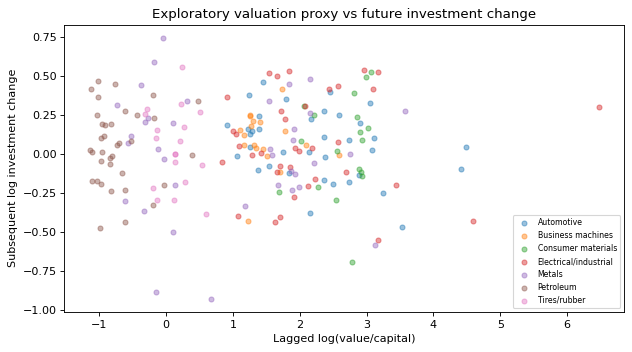

In [11]:
fig,ax=plt.subplots(figsize=(8,4.5))
for group,g in panel.groupby('group'):
    ax.scatter(g.q_proxy,g.log_invest-g.log_invest_lag,label=group,alpha=.45,s=20)
ax.set(xlabel='Lagged log(value/capital)',ylabel='Subsequent log investment change',title='Exploratory valuation proxy vs future investment change')
ax.legend(fontsize=7);plt.tight_layout();plt.show()

## 07. Exposure & Transmission

All 11 firms have a **unit exposure to their own** market-value-to-capital signal, with no synthetic revenue weights. The company-group map is descriptive only (confidence C; reconstructed in 2026, not 1930s–1950s contemporaneous segmentation). The economic channel is market valuation → expected profitability/financing opportunities → capital budget → measured gross investment. No sector aggregate is inferred from the 11-firm sample. Firm-specific ±20% factor multipliers probe proxy-construction sensitivity, not validated industry exposure weights.

In [12]:
display(exposure.groupby('descriptive_industry').agg(n_firms=('firm','nunique')).reset_index())
assert exposure.quantitative_revenue_weight.eq('UNKNOWN').all()

,descriptive_industry,n_firms
0,Automotive,2
1,Business machines,1
2,Consumer materials,1
3,Electrical/industrial,2
4,Metals,2
5,Petroleum,2
6,Tires/rubber,1


In [13]:
pert=pd.read_csv(ROOT/'results/exposure_perturbations.csv')
print('1000 firm-factor perturbations; positive RMSE gain fraction:',round((pert.rmse_improvement>0).mean(),4))
print('Gain quantiles:',pert.rmse_improvement.quantile([.05,.5,.95]).round(5).to_dict())

1000 firm-factor perturbations; positive RMSE gain fraction: 1.0
Gain quantiles: {0.05: 0.02559, 0.5: 0.03019, 0.95: 0.03398}


## 08. Outcomes & Baselines

The dependent variable is **observed real firm gross investment** in 1947-dollar millions, transformed to log units for estimation. Firm-specific historical means and persistence are strong baselines; multivariate Ridge adds lagged investment, capital and investment momentum. Both control and augmented models share identical 1945–1954 origins, 11 firms per origin, one-year target embargo and train-only transformations. For intuition, a 0.1 log-unit RMSE is approximately a 10% multiplicative error, not 0.1 percentage points. There are no annual total returns, stock-price ranks, benchmark-adjusted returns or transaction-cost backtests.

In [14]:
display(score.round(4));assert len(pred)==110
print('Same-origin comparison: 10 years × 11 firms, not 110 independent time clusters.')

,model,n,rmse_log,mae_log,rmse_invest_millions_1947
0,historical_mean,110,0.5358,0.4520,146.3435
1,persistence,110,0.2544,0.1990,60.8373
2,control,110,0.2929,0.2226,77.4115
3,full,110,0.2616,0.2029,74.5713


Same-origin comparison: 10 years × 11 firms, not 110 independent time clusters.


In [15]:
refit=walkforward(prepare(raw));computed=metrics(refit)
check=score.set_index('model').rmse_log.sort_index()-computed.set_index('model').rmse_log.sort_index()
print('Independent OOS refit RMSE maximum difference:',abs(check).max())
assert abs(check).max()<1e-11

Independent OOS refit RMSE maximum difference: 5.551115123125783e-17


## 09. Empirical Findings

The primary statistic is ΔRMSE = RMSE(control) − RMSE(full); positive favors the valuation proxy. The *decisive practical benchmark* is the best simple predictor, not just the control regression. We additionally calculate year-level errors, cumulative paired loss differences, and fundamental residual rank IC. These cross-sectional diagnostics measure **investment**, never securities returns; even a positive investment rank IC is not stock-market alpha.

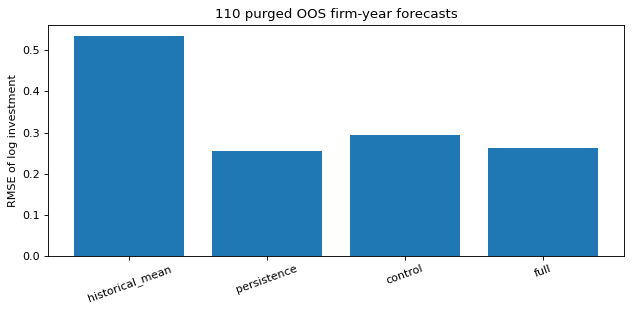

In [16]:
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(score.model,score.rmse_log);ax.set(ylabel='RMSE of log investment',title='110 purged OOS firm-year forecasts')
ax.tick_params(axis='x',rotation=20);plt.tight_layout();plt.show()

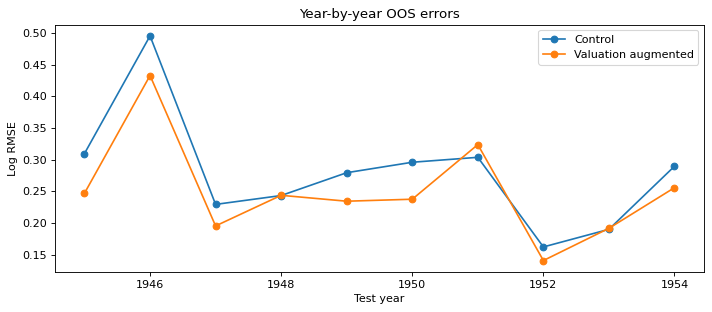

In [17]:
annual=pred.groupby('year').apply(lambda x:pd.Series({'control':np.sqrt(np.mean((x.control-x.truth)**2)), 'full':np.sqrt(np.mean((x.full-x.truth)**2))}),include_groups=False)
fig,ax=plt.subplots(figsize=(9,4));ax.plot(annual.index,annual.control,'o-',label='Control');ax.plot(annual.index,annual.full,'o-',label='Valuation augmented');ax.set(xlabel='Test year',ylabel='Log RMSE',title='Year-by-year OOS errors');ax.legend();plt.tight_layout();plt.show()

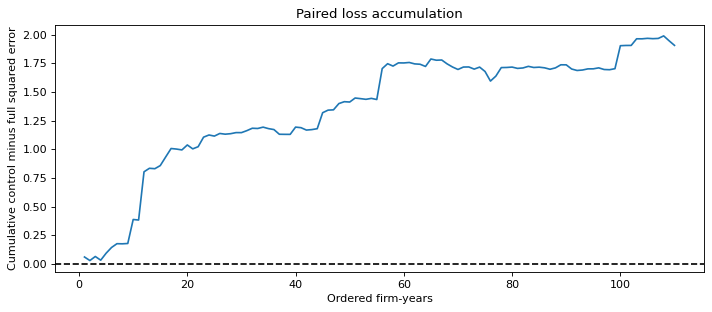

In [18]:
loss=(pred.control-pred.truth)**2-(pred.full-pred.truth)**2
fig,ax=plt.subplots(figsize=(9,4));ax.plot(np.arange(1,len(loss)+1),loss.cumsum());ax.axhline(0,color='black',linestyle='--');ax.set(xlabel='Ordered firm-years',ylabel='Cumulative control minus full squared error',title='Paired loss accumulation');plt.tight_layout();plt.show()

,year,n_firms,fundamental_residual_rank_ic,top3_minus_bottom3_realized_residual_log
0,1945,11,0.655,0.451
1,1946,11,0.755,0.890
2,1947,11,0.618,0.256
3,1948,11,0.436,0.400
4,1949,11,0.127,0.072
5,1950,11,0.582,0.427
6,1951,11,0.418,0.182
7,1952,11,0.764,0.278
8,1953,11,0.536,0.241
9,1954,11,0.291,0.248


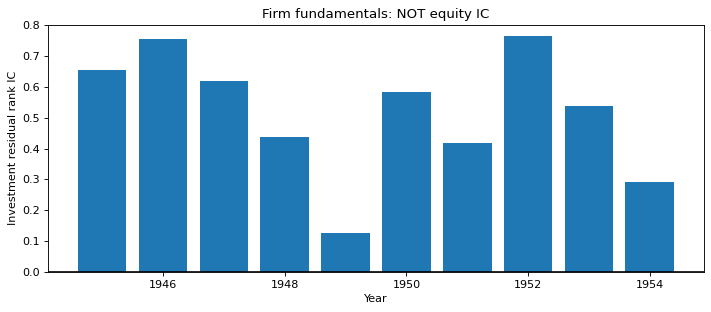

In [19]:
rank=rank_diagnostics(pred)
display(rank.round(3))
fig,ax=plt.subplots(figsize=(9,4));ax.bar(rank.year,rank.fundamental_residual_rank_ic);ax.axhline(0,color='black');ax.set(xlabel='Year',ylabel='Investment residual rank IC',title='Firm fundamentals: NOT equity IC');plt.tight_layout();plt.show()

In [20]:
rank_uncertainty=pd.read_csv(ROOT/'results/fundamental_rank_yearblock_uncertainty.csv')
assert len(rank_uncertainty)==2000
print('Exploratory 2-year year-block intervals for firm FUNDAMENTALS (not equity):')
display(rank_uncertainty[['mean_fundamental_rank_ic','mean_investment_residual_spread']].quantile([.025,.5,.975]).round(4))

Exploratory 2-year year-block intervals for firm FUNDAMENTALS (not equity):


,mean_fundamental_rank_ic,mean_investment_residual_spread
0.025,0.3964,0.2509
0.500,0.5182,0.3384
0.975,0.6318,0.4896


## 10. Robustness & Placebos

The archived **1,000-refit** placebo permutes contiguous three-year factor blocks **within each company**, preserving short local serial structure while breaking original year alignment; its tail fraction is exploratory, **not an exact randomization p-value**, because exchangeability and trends are not guaranteed. The **2,000-draw** paired circular two-year block bootstrap resamples whole years across all 11 firms, preserving within-year cross-sectional dependence. We also test 1,000 company-specific ±20% factor perturbations and 11 leave-one-company-out re-estimations. Full draws are produced by `python run_analysis.py`, while this notebook independently checks saved draw counts and core refit scores.

In [21]:
placebo=pd.read_csv(ROOT/'results/block_shuffle_placebo.csv');boot=pd.read_csv(ROOT/'results/bootstrap_year_blocks.csv')
assert len(placebo)==1000 and len(boot)==2000 and len(pert)==1000
observed=improvement(pred)
tail=(1+(placebo.rmse_improvement>=observed).sum())/(len(placebo)+1)
ci=boot.rmse_improvement.quantile([.025,.975]).to_numpy()
print('Observed ΔRMSE:',round(observed,6),'exploratory block-shuffle upper-tail fraction:',round(tail,4),'year-block CI:',np.round(ci,5))

Observed ΔRMSE: 0.031281 exploratory block-shuffle upper-tail fraction: 0.003 year-block CI: [0.01123 0.04885]


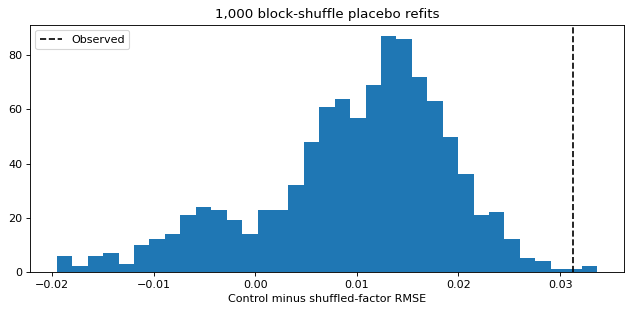

In [22]:
fig,ax=plt.subplots(figsize=(8,4));ax.hist(placebo.rmse_improvement,bins=35);ax.axvline(observed,color='black',linestyle='--',label='Observed');ax.set(xlabel='Control minus shuffled-factor RMSE',title='1,000 block-shuffle placebo refits');ax.legend();plt.tight_layout();plt.show()

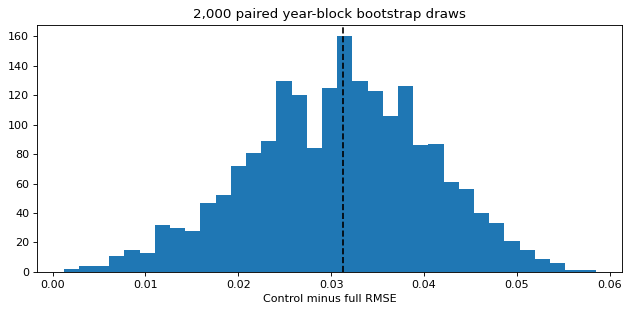

In [23]:
fig,ax=plt.subplots(figsize=(8,4));ax.hist(boot.rmse_improvement,bins=35);ax.axvline(observed,color='black',linestyle='--');ax.set(xlabel='Control minus full RMSE',title='2,000 paired year-block bootstrap draws');plt.tight_layout();plt.show()

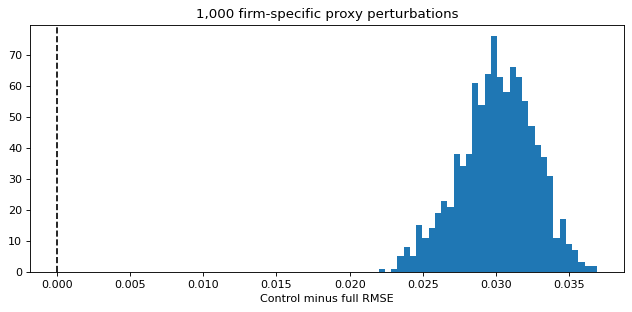

In [24]:
fig,ax=plt.subplots(figsize=(8,4));ax.hist(pert.rmse_improvement,bins=35);ax.axvline(0,color='black',linestyle='--');ax.set(xlabel='Control minus full RMSE',title='1,000 firm-specific proxy perturbations');plt.tight_layout();plt.show()

,excluded_firm,n,rmse_improvement,control_rmse,full_rmse
0,American Steel,100,0.0164,0.2520,0.2356
1,Atlantic Refining,100,0.0357,0.3068,0.2711
2,Chrysler,100,0.0370,0.3010,0.2640
3,Diamond Match,100,0.0215,0.2919,0.2704
4,General Electric,100,0.0350,0.2998,0.2648
5,General Motors,100,0.0266,0.2999,0.2734
6,Goodyear,100,0.0357,0.3046,0.2690
7,IBM,100,0.0338,0.3076,0.2738
8,US Steel,100,0.0292,0.2919,0.2626
9,Union Oil,100,0.0345,0.3024,0.2680


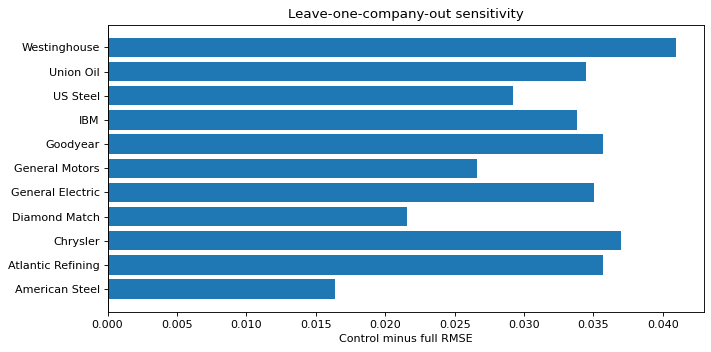

In [25]:
loo=pd.read_csv(ROOT/'results/leave_one_company_out.csv')
display(loo.round(4))
fig,ax=plt.subplots(figsize=(9,4.5));ax.barh(loo.excluded_firm,loo.rmse_improvement);ax.axvline(0,color='black');ax.set(xlabel='Control minus full RMSE',title='Leave-one-company-out sensitivity');plt.tight_layout();plt.show()

## 11. Regime Sensitivity

Two short five-year postwar blocks are reported rather than interpreted as independent regimes with reliable power. Alternative lagged-feature horizons (1/2/3 years), the known 1946 US Steel capital correction, and control-feature ablations test stability. Because the sample includes wartime and postwar investment transitions, any generalization to 2026 would be especially inappropriate. These are exploratory checks after observing the main sample, not a protected holdout.

In [26]:
rob=pd.read_csv(ROOT/'results/robustness_scenarios.csv');display(rob.round(5))
print('Sign changes:',int((rob.rmse_improvement<0).sum()),'of',len(rob),'scenarios')

,scenario,n,rmse_improvement
0,feature_lag_1y,110,0.03128
1,feature_lag_2y,110,0.03336
2,feature_lag_3y,110,0.03352
3,1945_1949,55,0.04284
4,1950_1954,55,0.01740
5,us_steel_1946_capital_corrected,110,0.03119
6,no_invest_momentum,110,0.02895
7,no_capital,110,-0.00214
8,no_invest_level,110,0.28112


Sign changes: 1 of 9 scenarios


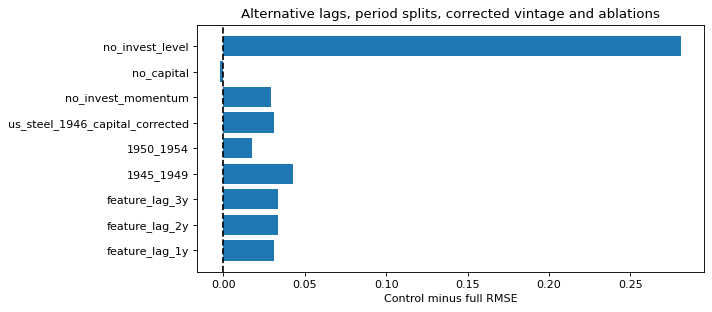

In [27]:
fig,ax=plt.subplots(figsize=(9,4));ax.barh(rob.scenario,rob.rmse_improvement);ax.axvline(0,color='black',linestyle='--');ax.set(xlabel='Control minus full RMSE',title='Alternative lags, period splits, corrected vintage and ablations');plt.tight_layout();plt.show()

## 12. Bias Audit & Verdict

**Vintage/look-ahead:** raw Grunfeld data were assembled and revised after 1954; the mechanical lag and target embargo are not verified historical availability. **Selection/survivorship:** 11 selected firms, no historical complete investable universe. **Multiple testing:** a family of robustness variants is descriptive, not a multiplicity-adjusted discovery claim. **Mechanical overlap:** q̃ shares capital with controls and firm fixed effects; coefficient is not structural Tobin's q. **Structural breaks:** war/postwar and industrial composition. **Trading:** no total returns, delistings, spreads, commissions, taxes, market impact or capacity. A fundamental forecasting result cannot be translated into investable equity alpha.

In [28]:
bias=pd.DataFrame([
 ['Historical release vintages','Unavailable','NOT PIT'],['Source-version correction','US Steel 1946 capital mismatch','Sensitivity tested'],
 ['Survivorship/selection','11 named historical firms','No population inference'],['Multiple testing','Several lag/ablation/regime variants','Exploratory'],
 ['Overlapping factor/control','Capital denominator shared','Ablation checked'],['Equity returns/costs','Not collected','No equity alpha']
],columns=['Risk','Observed limitation','Treatment']);display(bias)

,Risk,Observed limitation,Treatment
0,Historical release vintages,Unavailable,NOT PIT
1,Source-version correction,US Steel 1946 capital mismatch,Sensitivity tested
2,Survivorship/selection,11 named historical firms,No population inference
3,Multiple testing,Several lag/ablation/regime variants,Exploratory
4,Overlapping factor/control,Capital denominator shared,Ablation checked
5,Equity returns/costs,Not collected,No equity alpha


## 13. Reproduction

From the study folder: `python -m pip install -r requirements.txt`; `python run_analysis.py` reproduces 1,000 placebo refits, 2,000 paired year-block bootstrap draws, 1,000 perturbation refits and all OOS tables; `python make_figures.py` produces SVG diagnostics; `python -m pytest -q tests` runs unit tests. To re-execute this notebook: `jupyter nbconvert --to notebook --execute --inplace research.ipynb` or `nbclient` with the study folder as working directory. The notebook reads the committed full-draw files and **recomputes OOS scores independently**; it does not repeat the expensive 4,000 resampling refits. CI layout checks are separate from numerical reproduction.

In [29]:
import hashlib
f=ROOT/'data/grunfeld_statsmodels_0_14_6_frozen.csv'
sha=hashlib.sha256(f.read_bytes()).hexdigest()
print('Frozen raw SHA-256:',sha)
assert sha=='502c3a22b87e04fd4545ffe4807bf423d2fc7bb0e9847887b725120efa0b2ace'
print('Resampling rows:',len(placebo),len(boot),len(pert),'OOS predictions:',len(pred))

Frozen raw SHA-256: 502c3a22b87e04fd4545ffe4807bf423d2fc7bb0e9847887b725120efa0b2ace
Resampling rows: 1000 2000 1000 OOS predictions: 110


In [30]:
artifact_check=pd.DataFrame([
 ['raw',len(raw)],['derived_panel',len(pd.read_csv(ROOT/'data/derived_panel.csv'))],
 ['OOS_predictions',len(pd.read_csv(ROOT/'results/oos_predictions.csv'))],
 ['bootstrap_draws',len(boot)],['placebo_refits',len(placebo)],['proxy_perturbations',len(pert)],
 ['LOCO',len(loo)]],columns=['artifact','rows']);display(artifact_check)

,artifact,rows
0,raw,220
1,derived_panel,198
2,OOS_predictions,110
3,bootstrap_draws,2000
4,placebo_refits,1000
5,proxy_perturbations,1000
6,LOCO,11


## 14. Next-Stage Protocol

A modern follow-up should use a **predeclared current industrial universe**, issuer-level capital expenditure and investment plans from dated SEC 10-K/10-Q filings, market-value and debt snapshots as of formation, and independent total-return data including delistings. Obtain true filing timestamps and historical data vintages before training; use quarterly purged OOS, sector/size/momentum controls, a protected final holdout, and multiple-testing adjustment. Estimate portfolio turnover, bid/ask, impact and tax costs only after a legitimate return target exists. The historical Grunfeld exercise is a methods and data-integrity benchmark, not an investment recommendation.

In [31]:
protocol=pd.DataFrame([
 ['Filing-vintage capex','SEC 10-K/10-Q XBRL with filing acceptance timestamps','PIT corporate fundamentals'],
 ['Market-value and capital proxies','dated shares, debt, assets, price history','formation-time signal'],
 ['Returns and delistings','total-return security database + benchmark','independent investable outcome'],
 ['Audit','rolling purge + false-discovery correction + costs','release gate']
],columns=['Dataset','Collection requirement','Purpose']);display(protocol)

,Dataset,Collection requirement,Purpose
0,Filing-vintage capex,SEC 10-K/10-Q XBRL with filing acceptance time...,PIT corporate fundamentals
1,Market-value and capital proxies,"dated shares, debt, assets, price history",formation-time signal
2,Returns and delistings,total-return security database + benchmark,independent investable outcome
3,Audit,rolling purge + false-discovery correction + c...,release gate


## 15. Sources & Artifacts

**Primary attribution:** Grunfeld (1958), original dissertation (not directly inspected). **Distributed raw data:** statsmodels Grunfeld (1950) dataset, frozen from 0.14.6. **Independent discrepancy audit:** CRAN AER Grunfeld documentation and Kleiber & Zeileis (2010), *The Grunfeld Data at 50*. **Theory:** Fazzari, Hubbard & Petersen (1987), NBER Working Paper 2387. All exact URLs, publication dates or UNKNOWN fields, observation periods and revision flags are in `data/source_register.csv`. Source grades refer to provenance, not historical PIT availability.

In [32]:
display(sources[['source_id','grade','url','publication_date','version_or_vintage','pit_status']])
print('Figures:',len(list((ROOT/'figures').glob('*.svg'))),'saved SVG diagnostics')

,source_id,grade,url,publication_date,version_or_vintage,pit_status
0,S01,B,https://www.statsmodels.org/v0.12.2/datasets/g...,UNKNOWN,statsmodels 0.14.6 frozen CSV SHA-256 in data/...,NOT_PIT
1,S02,B,https://github.com/statsmodels/statsmodels/blo...,UNKNOWN,repository main viewed 2026-10-27; package fro...,NOT_PIT
2,S03,B,https://search.r-project.org/CRAN/refmans/AER/...,UNKNOWN,CRAN AER online documentation retrieved 2026-1...,NOT_PIT
3,S04,A,https://search.r-project.org/CRAN/refmans/AER/...,1958,1958 dissertation cited by secondary documenta...,NOT_PIT
4,S05,B,https://www.zeileis.org/papers/Kleiber%2BZeile...,2010,2010 peer-reviewed reconstruction,NOT_PIT
5,S06,B,https://www.nber.org/papers/w2387,1987-09,NBER working paper 2387,NOT_APPLICABLE
6,S07,C,https://github.com/HyeonbinJung/Signals-to-Alp...,2026-10-27,Manual name-based groups 2026-10-27,NOT_PIT


Figures: 10 saved SVG diagnostics


### Final verdict

A positive control-model gain would be **a retrospective firm-level investment forecast result**, not evidence of stock-return alpha. The decisive evaluation also compares against persistence, bootstrap uncertainty, company exclusions, source-version correction and historically non-PIT data. Report the actual numerical result below, rather than interpreting this historical panel as a 2026 trading strategy.

In [33]:
score_idx=score.set_index('model')
print('Control RMSE:',round(score_idx.loc['control','rmse_log'],6))
print('Valuation-augmented RMSE:',round(score_idx.loc['full','rmse_log'],6))
print('Persistence RMSE:',round(score_idx.loc['persistence','rmse_log'],6))
print('Bootstrap 95% interval:',np.round(ci,6).tolist())
print('Verdict: REPRODUCED RETROSPECTIVE FIRM-FUNDAMENTALS PILOT; NOT PIT; NOT INVESTABLE EQUITY ALPHA')

Control RMSE: 0.292893
Valuation-augmented RMSE: 0.261612
Persistence RMSE: 0.254374
Bootstrap 95% interval: [0.011234, 0.048846]
Verdict: REPRODUCED RETROSPECTIVE FIRM-FUNDAMENTALS PILOT; NOT PIT; NOT INVESTABLE EQUITY ALPHA
